# Разведочный анализ данных (EDA) и прототип системы прогнозирования мощности электростанции (CCPP)

**Задача:** Проанализировать метеорологические и производственные параметры парогазовой электростанции (Combined Cycle Power Plant), выявить наиболее значимые факторы и разработать интерактивный прототип для прогнозирования выработки электроэнергии (`PE`).

**Источник данных:** [UCI Machine Learning Repository — Combined Cycle Power Plant (ID: 294)](https://archive.ics.uci.edu/dataset/294/combined%2Bcycle%2Bpower%2Bplant)

In [ ]:
# Установка необходимых библиотек (раскомментируйте при необходимости)
# !pip install pandas numpy matplotlib seaborn scikit-learn openpyxl ipywidgets

In [1]:
import io
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import ipywidgets as widgets
from IPython.display import display

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

## 1. Загрузка данных и первичный осмотр

In [2]:
# Прямая загрузка архива с UCI Machine Learning Repository
url = "https://archive.ics.uci.edu/static/public/294/combined+cycle+power+plant.zip"
response = urllib.request.urlopen(url)

with zipfile.ZipFile(io.BytesIO(response.read())) as z:
    # В архиве находится папка CCPP с файлом Folds5x2_pp.xlsx
    xlsx_files = [f for f in z.namelist() if f.endswith(".xlsx")]
    with z.open(xlsx_files[0]) as f:
        df = pd.read_excel(f)

print(f"Размерность датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
df.head()

Размерность датасета: 9568 строк, 5 столбцов


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [3]:
# Проверка типов данных и пропусков
info_df = pd.DataFrame({
    "Тип данных": df.dtypes,
    "Пропуски (шт.)": df.isnull().sum(),
    "Пропуски (%)": (df.isnull().sum() / len(df)) * 100,
    "Уникальные значения": df.nunique()
})
display(info_df)

duplicates = df.duplicated().sum()
print(f"Количество полных дубликатов строк: {duplicates}")

,Тип данных,Пропуски (шт.),Пропуски (%),Уникальные значения
AT,float64,0,0.0,2773
V,float64,0,0.0,634
AP,float64,0,0.0,2517
RH,float64,0,0.0,4546
PE,float64,0,0.0,4836


Количество полных дубликатов строк: 41


In [4]:
# Очистка от полных дубликатов для корректного анализа и обучения
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Размерность после удаления дубликатов: {df_clean.shape}")

# Описательная статистика
desc = df_clean.describe().T
desc["IQR"] = desc["75%"] - desc["25%"]
display(desc)

Размерность после удаления дубликатов: (9527, 5)


,count,mean,std,min,25%,50%,75%,max,IQR
AT,9527.0,19.658225,7.444397,1.81,13.530,20.35,25.710,37.11,12.180
V,9527.0,54.293421,12.686309,25.36,41.740,52.08,66.510,81.56,24.770
AP,9527.0,1013.237084,5.940526,992.89,1009.085,1012.92,1017.200,1033.30,8.115
RH,9527.0,73.334951,14.607513,25.56,63.375,75.00,84.850,100.16,21.475
PE,9527.0,454.335910,17.039080,420.26,439.750,451.52,468.365,495.76,28.615


## 2. Анализ распределений и проверка на выбросы

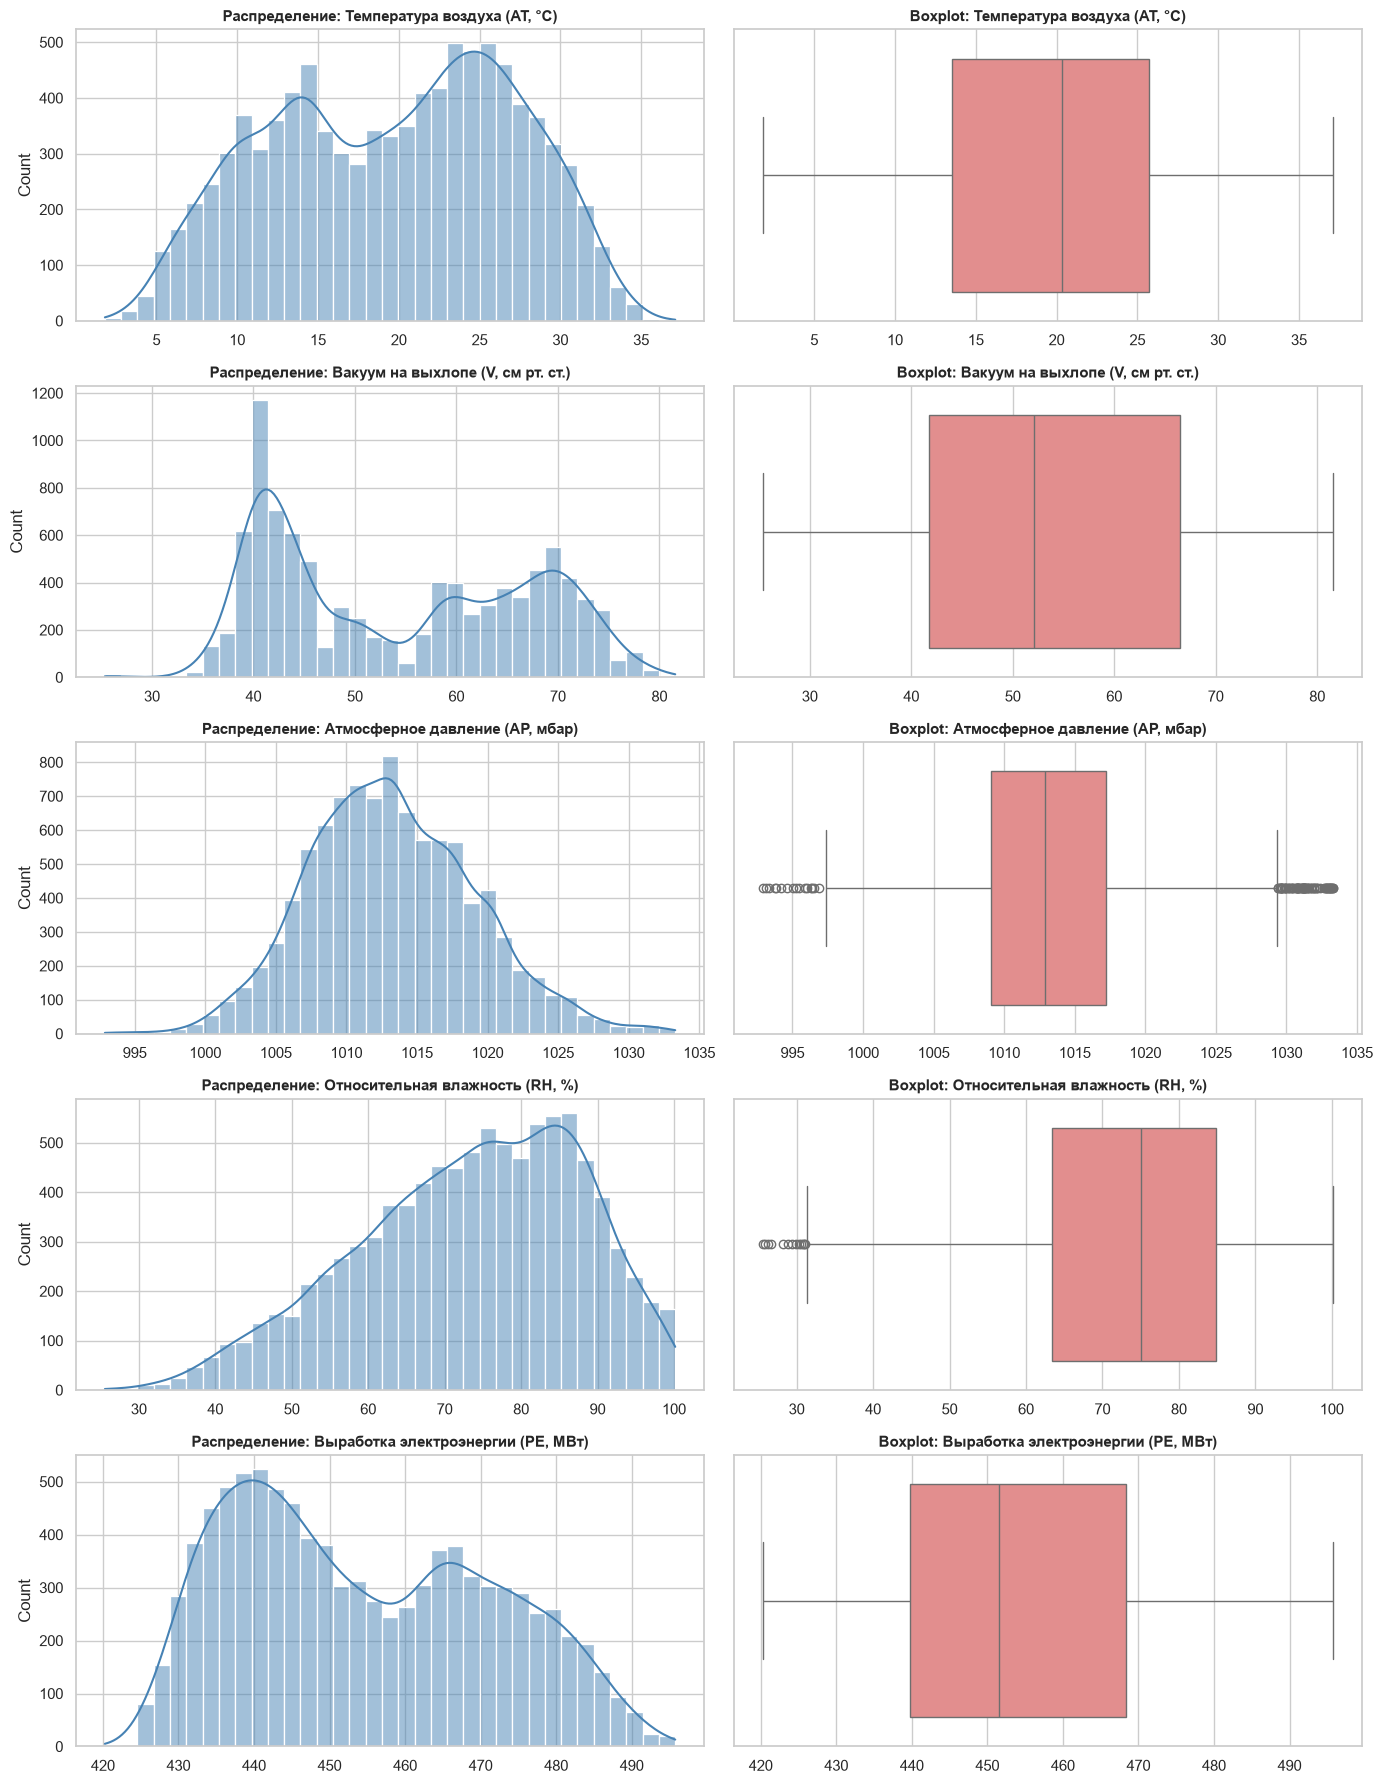

In [5]:
feature_names = {
    "AT": "Температура воздуха (AT, °C)",
    "V": "Вакуум на выхлопе (V, см рт. ст.)",
    "AP": "Атмосферное давление (AP, мбар)",
    "RH": "Относительная влажность (RH, %)",
    "PE": "Выработка электроэнергии (PE, МВт)"
}

fig, axes = plt.subplots(len(df_clean.columns), 2, figsize=(14, 18))

for i, col in enumerate(df_clean.columns):
    # Гистограмма + KDE
    sns.histplot(df_clean[col], kde=True, ax=axes[i, 0], color="steelblue", bins=35)
    axes[i, 0].set_title(f"Распределение: {feature_names[col]}", fontsize=11, fontweight="bold")
    axes[i, 0].set_xlabel("")
    
    # Boxplot для оценки выбросов
    sns.boxplot(x=df_clean[col], ax=axes[i, 1], color="lightcoral")
    axes[i, 1].set_title(f"Boxplot: {feature_names[col]}", fontsize=11, fontweight="bold")
    axes[i, 1].set_xlabel("")

plt.tight_layout()
plt.show()

**Наблюдения по распределениям:**
* **Температура (`AT`)** и **вакуум (`V`)** имеют бимодальное распределение (два выраженных пика), что соответствовать сезонным режимам работы станции (зима / лето).
* **Атмосферное давление (`AP`)** и **влажность (`RH`)** распределены близко к нормальному (с небольшой левосторонней асимметрией у влажности). Единичные точки за усами boxplot у `AP` и `RH` соответствуют реальным погодным экстремумам (циклоны, сухая погода) и не являются ошибками датчиков.

## 3. Корреляционный анализ и зависимости с целевой переменной (`PE`)

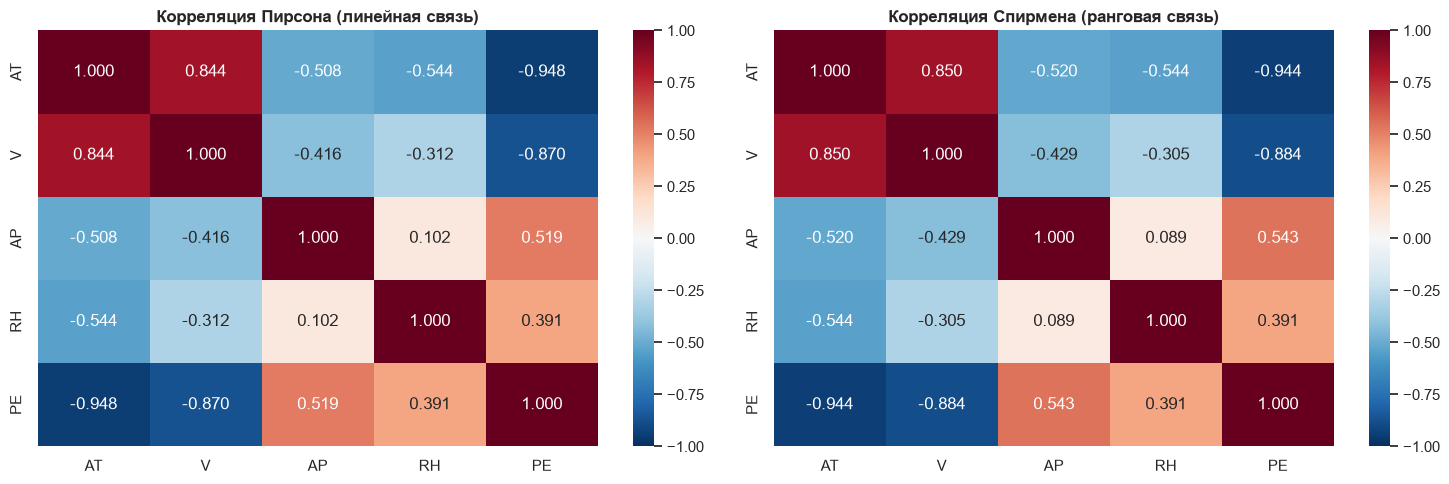

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Корреляция Пирсона (линейная)
sns.heatmap(df_clean.corr(method="pearson"), annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Корреляция Пирсона (линейная связь)", fontweight="bold")

# Корреляция Спирмена (монотонная)
sns.heatmap(df_clean.corr(method="spearman"), annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Корреляция Спирмена (ранговая связь)", fontweight="bold")

plt.tight_layout()
plt.show()

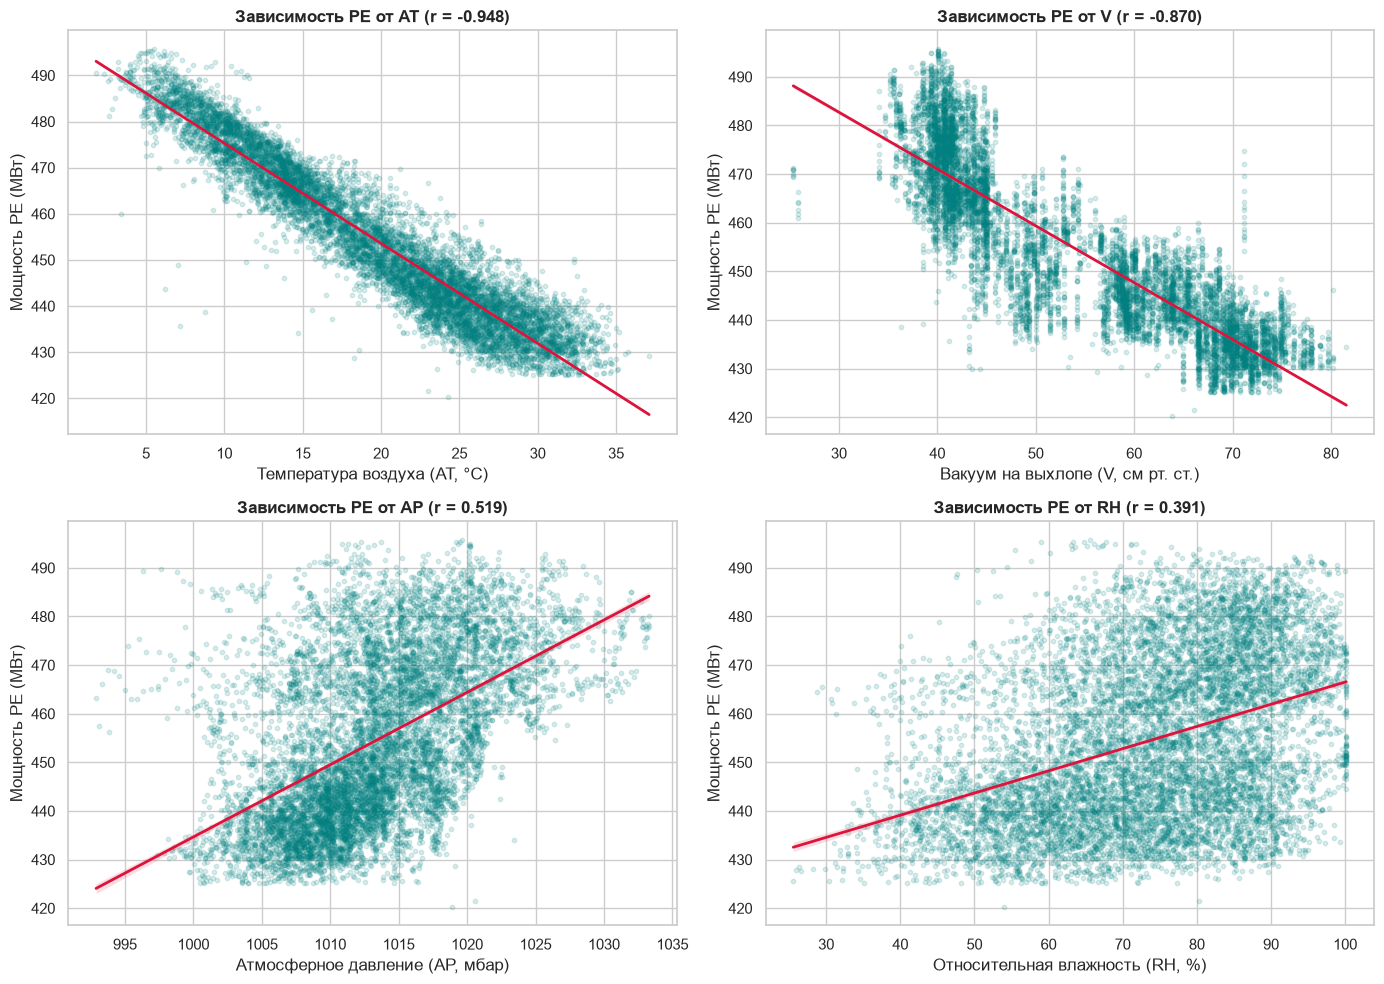

In [7]:
# Диаграммы рассеяния (Scatter plots) с линией тренда
features = ["AT", "V", "AP", "RH"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.regplot(
        data=df_clean, x=col, y="PE",
        ax=axes[i],
        scatter_kws={"alpha": 0.15, "s": 10, "color": "teal"},
        line_kws={"color": "crimson", "linewidth": 2}
    )
    corr_val = df_clean[col].corr(df_clean["PE"])
    axes[i].set_title(f"Зависимость PE от {col} (r = {corr_val:.3f})", fontweight="bold")
    axes[i].set_xlabel(feature_names[col])
    axes[i].set_ylabel("Мощность PE (МВт)")

plt.tight_layout()
plt.show()

## 4. Оценка значимости признаков (Feature Importance) и сравнение моделей

In [8]:
X = df_clean[["AT", "V", "AP", "RH"]]
y = df_clean["PE"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    results.append({
        "Модель": name,
        "MAE (МВт)": round(mean_absolute_error(y_test, preds), 3),
        "RMSE (МВт)": round(np.sqrt(mean_squared_error(y_test, preds)), 3),
        "R2": round(r2_score(y_test, preds), 4)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Модель,MAE (МВт),RMSE (МВт),R2
0,Linear Regression,3.621,4.587,0.9284
1,Gradient Boosting,2.839,3.810,0.9506
2,Random Forest,2.417,3.447,0.9596


,Признак,Описание,Gini Importance,Permutation Importance (падение R2)
0,AT,"Температура воздуха (AT, °C)",0.900862,1.488091
1,V,"Вакуум на выхлопе (V, см рт. ст.)",0.062314,0.094053
3,RH,"Относительная влажность (RH, %)",0.017622,0.022131
2,AP,"Атмосферное давление (AP, мбар)",0.019201,0.019669


/var/folders/rl/z0xy7t9n3994_kw8nb1wb3900000gn/T/ipykernel_14532/1453987039.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp_df, x="Permutation Importance (падение R2)", y="Описание", palette="viridis")


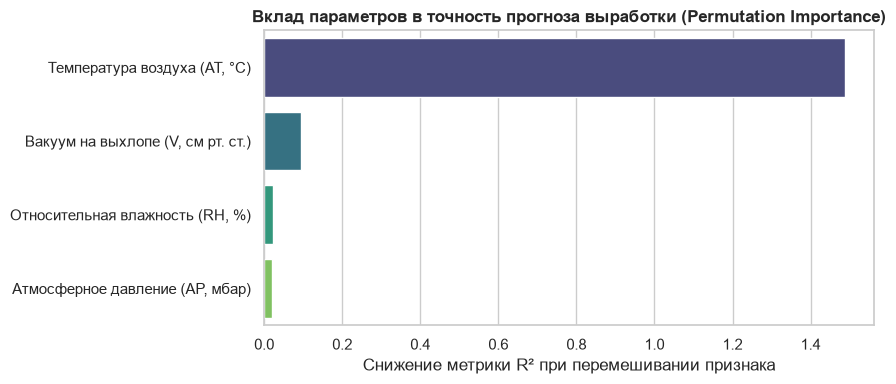

In [9]:
rf_model = models["Random Forest"]
perm_imp = permutation_importance(rf_model, X_test, y_test, n_repeats=15, random_state=42, n_jobs=-1)

imp_df = pd.DataFrame({
    "Признак": X.columns,
    "Описание": [feature_names[c] for c in X.columns],
    "Gini Importance": rf_model.feature_importances_,
    "Permutation Importance (падение R2)": perm_imp.importances_mean
}).sort_values(by="Permutation Importance (падение R2)", ascending=False)

display(imp_df)

plt.figure(figsize=(9, 4))
sns.barplot(data=imp_df, x="Permutation Importance (падение R2)", y="Описание", palette="viridis")
plt.title("Вклад параметров в точность прогноза выработки (Permutation Importance)", fontweight="bold")
plt.xlabel("Снижение метрики R² при перемешивании признака")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 5. Интерактивный симулятор прогнозирования выработки станции

In [11]:
# Интерактивный виджет для изменения параметров и расчёта мощности PE
style = {"description_width": "220px"}
layout = widgets.Layout(width="550px")

at_slider = widgets.FloatSlider(value=19.6, min=1.8, max=37.1, step=0.1, description="Температура воздуха AT (°C):", style=style, layout=layout)
v_slider = widgets.FloatSlider(value=54.3, min=25.3, max=81.6, step=0.1, description="Вакуум на выхлопе V (см рт.ст.):", style=style, layout=layout)
ap_slider = widgets.FloatSlider(value=1013.3, min=992.9, max=1033.3, step=0.1, description="Атм. давление AP (мбар):", style=style, layout=layout)
rh_slider = widgets.FloatSlider(value=73.3, min=25.5, max=100.0, step=0.5, description="Отн. влажность RH (%):", style=style, layout=layout)

output_box = widgets.Output()

def update_prediction(*args):
    with output_box:
        output_box.clear_output()
        input_data = pd.DataFrame([{
            "AT": at_slider.value,
            "V": v_slider.value,
            "AP": ap_slider.value,
            "RH": rh_slider.value
        }])
        pred_rf = rf_model.predict(input_data)[0]
        pred_lr = models["Linear Regression"].predict(input_data)[0]
        
        print("=" * 55)
        print(f"Прогноз мощности (Random Forest):     {pred_rf:.2f} МВт")
        print(f"Прогноз мощности (Linear Regression): {pred_lr:.2f} МВт")
        print("=" * 55)

for slider in [at_slider, v_slider, ap_slider, rh_slider]:
    slider.observe(update_prediction, names="value")

display(widgets.VBox([at_slider, v_slider, ap_slider, rh_slider, output_box]))
update_prediction()